Vocabulary size: 94


Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_3       │ (None, 6)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ token_position_emb… │ (None, 6, 32)     │      3,200 │ input_layer_3[0]… │
│ (TokenPositionEmbe… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 6, 32)     │      4,224 │ token_position_e… │
│ (MultiHeadAttentio… │                   │            │ token_position_e… │
│                     │                   │            │ token_position_e… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_6 (Add)         │ (None, 6, 32)     │          0 │ token_position_e… │
│                     │                   │            │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 6, 32)     │         64 │ add_6[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_9 (Dense)     │ (None, 6, 64)     │      2,112 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_10 (Dense)    │ (None, 6, 32)     │      2,080 │ dense_9[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_7 (Add)         │ (None, 6, 32)     │          0 │ layer_normalizat… │
│                     │                   │            │ dense_10[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 6, 32)     │         64 │ add_7[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lambda_3 (Lambda)   │ (None, 32)        │          0 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_11 (Dense)    │ (None, 94)        │      3,102 │ lambda_3[0][0]    │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 14,846 (57.99 KB)

 Trainable params: 14,846 (57.99 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 5s 60ms/step - accuracy: 0.0078 - loss: 4.7102 - val_accuracy: 0.0667 - val_loss: 4.6026
Epoch 2/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.1163 - loss: 4.2227 - val_accuracy: 0.1333 - val_loss: 4.5627
Epoch 3/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.1395 - loss: 3.9654 - val_accuracy: 0.1333 - val_loss: 4.4687
Epoch 4/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.2016 - loss: 3.6763 - val_accuracy: 0.2667 - val_loss: 4.3493
Epoch 5/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.2868 - loss: 3.3673 - val_accuracy: 0.2000 - val_loss: 4.2813
Epoch 6/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.3876 - loss: 3.0925 - val_accuracy: 0.2000 - val_loss: 4.2386
Epoch 7/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.4961 - loss: 2.8512 - val_accuracy: 0.2000 - val_loss: 4.1937
Epoch 8/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.5581 - loss: 2.6377 - val_accuracy: 0.2000 - val_loss:

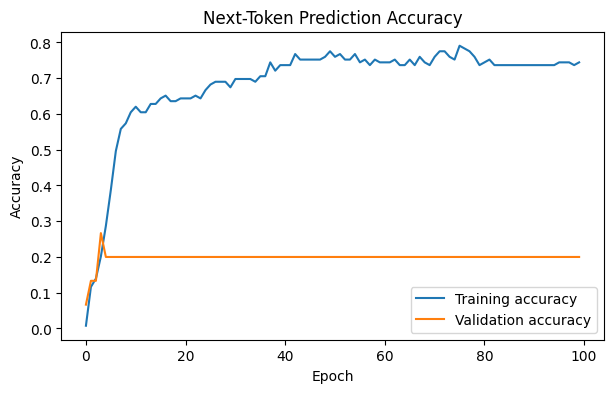

Text(value='the cat is', description='Input:', layout=Layout(width='80%'), placeholder='Enter a sentence...')

Button(button_style='primary', description='Predict Next Word', style=ButtonStyle())

Output()

In [ ]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras import layers, Model
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

import ipywidgets as widgets
from IPython.display import display, clear_output

tf.keras.utils.set_random_seed(42)

# 1. Training dataset
texts = [
    "the cat is sleeping",
    "the cat is playing",
    "the cat drinks milk",
    "the dog is running",
    "the dog is playing",
    "the dog eats food",
    "the bird is flying",
    "the bird is singing",
    "the sun is shining",
    "the moon shines at night",
    "machine learning is useful",
    "deep learning uses neural networks",
    "artificial intelligence helps people",
    "transformers use self attention",
    "self attention understands context",
    "language models predict the next word",
    "python is a programming language",
    "students learn python programming",
    "students write code",
    "the teacher teaches students",
    "the boy plays football",
    "the girl reads books",
    "the flowers grow in the garden",
    "the trees provide fresh air",
    "water is essential for life",
    "computers process information",
    "data helps models learn",
    "neural networks learn patterns",
    "the puppy plays in the garden",
    "the cat sleeps on the sofa",
    "the dog sleeps on the floor",
    "the bird sits on a tree",
    "machine learning models learn patterns",
    "a transformer predicts the next token",
    "attention focuses on important words",
    "the student learns machine learning",
    "the student writes python code",
    "the dog runs in the park",
    "the cat drinks fresh milk",
    "artificial intelligence uses data"
]

# 2. Tokenization
MAX_LEN = 6
EMBED_DIM = 32
NUM_HEADS = 2

tokenizer = Tokenizer(oov_token="<OOV>")
tokenizer.fit_on_texts(texts)

vocab_size = len(tokenizer.word_index) + 1

print("Vocabulary size:", vocab_size)

# 3. Prepare next-token training examples
X, y = [], []

for sentence in texts:
    ids = tokenizer.texts_to_sequences([sentence])[0]

    for i in range(1, len(ids)):
        context = ids[max(0, i - MAX_LEN):i]

        context = pad_sequences(
            [context],
            maxlen=MAX_LEN,
            padding="pre",
            truncating="pre"
        )[0]

        X.append(context)
        y.append(ids[i])

X = np.array(X, dtype=np.int32)
y = np.array(y, dtype=np.int32)

# 4. Build Transformer with causal self-attention
class TokenPositionEmbedding(layers.Layer):
    def __init__(self, vocab_size, max_len, embed_dim):
        super().__init__()
        self.token_embedding = layers.Embedding(
            vocab_size, embed_dim
        )
        self.position_embedding = layers.Embedding(
            max_len, embed_dim
        )

    def call(self, token_ids):
        positions = tf.range(tf.shape(token_ids)[1])
        return (
            self.token_embedding(token_ids)
            + self.position_embedding(positions)
        )

inputs = layers.Input(shape=(MAX_LEN,), dtype=tf.int32)

x = TokenPositionEmbedding(
    vocab_size, MAX_LEN, EMBED_DIM
)(inputs)

attention = layers.MultiHeadAttention(
    num_heads=NUM_HEADS,
    key_dim=EMBED_DIM // NUM_HEADS
)(
    query=x,
    value=x,
    key=x,
    use_causal_mask=True
)

x = layers.Add()([x, attention])
x = layers.LayerNormalization()(x)

ffn = layers.Dense(64, activation="relu")(x)
ffn = layers.Dense(EMBED_DIM)(ffn)

x = layers.Add()([x, ffn])
x = layers.LayerNormalization()(x)

x = layers.Lambda(lambda t: t[:, -1, :])(x)
outputs = layers.Dense(
    vocab_size, activation="softmax"
)(x)

model = Model(inputs, outputs)

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

# 5. Train model
history = model.fit(
    X, y,
    epochs=100,
    batch_size=16,
    validation_split=0.1,
    verbose=1,
    shuffle=True
)

# 6. Show training accuracy
plt.figure(figsize=(7, 4))
plt.plot(history.history["accuracy"], label="Training accuracy")
plt.plot(history.history["val_accuracy"], label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Next-Token Prediction Accuracy")
plt.legend()
plt.show()

# 7. Predict next word for user-entered text
def predict_next_word(sentence):
    token_ids = tokenizer.texts_to_sequences([sentence])[0]

    # Ignore words that are not in the training vocabulary
    token_ids = [
        token for token in token_ids
        if token != tokenizer.word_index["<OOV>"]
    ]

    if not token_ids:
        print("No known words found. Try a sentence using the training vocabulary.")
        return

    context = token_ids[-MAX_LEN:]

    padded = pad_sequences(
        [context],
        maxlen=MAX_LEN,
        padding="pre",
        truncating="pre"
    )

    probabilities = model.predict(padded, verbose=0)[0].copy()

    # Prevent special tokens from being predicted
    probabilities[0] = 0
    probabilities[tokenizer.word_index["<OOV>"]] = 0

    predicted_id = int(np.argmax(probabilities))
    predicted_word = tokenizer.index_word.get(
        predicted_id, "<unknown>"
    )

    confidence = float(probabilities[predicted_id]) * 100

    print("Input sentence:", sentence)
    print("Predicted next word:", predicted_word)
    print(f"Model confidence: {confidence:.2f}%")

# 8. Interactive input box in Colab
sentence_box = widgets.Text(
    value="the cat is",
    placeholder="Enter a sentence...",
    description="Input:",
    layout=widgets.Layout(width="80%")
)

predict_button = widgets.Button(
    description="Predict Next Word",
    button_style="primary"
)

result_output = widgets.Output()

def on_predict_clicked(button):
    with result_output:
        clear_output(wait=True)
        predict_next_word(sentence_box.value)

predict_button.on_click(on_predict_clicked)

display(sentence_box, predict_button, result_output)